<a href="https://colab.research.google.com/github/rahs2015/mat422/blob/main/MAT_422_%7C_HW_3_7.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#MAT 422 - Section 3.7: Artificial Neural Networks

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

##3.7.1
The mathmatical model learns pattersn from data. It uses weights, biases, and actvitation function. It uses each of them to caluclate a weighted sum. In the example below, the neural network has 2 input variables, three neurons in the hidden layer, and 1 output neuron. The inputs shows hours studied and practice question compelted while the output represents the predicted probability of passing.

In [9]:
X = np.array([
    [2, 10],
    [4, 20],
    [6, 30],
    [8, 40]
])

W1 = np.array([
    [0.2, 0.4, 0.3],
    [0.5, 0.1, 0.6]
])


b1 = np.array([0.1, 0.2, 0.1])
W2 = np.array([
    [0.3],
    [0.5],
    [0.4]
])

b2 = np.array([0.2])
z1 = X @ W1 + b1
a1 = np.tanh(z1)
z2 = a1 @ W2 + b2
output = 1 / (1 + np.exp(-z2))

print("Hidden layer values:")
print(a1)

print("\nPredicted probabilities:")
print(output)

Hidden layer values:
[[1.    0.964 1.   ]
 [1.    0.999 1.   ]
 [1.    1.    1.   ]
 [1.    1.    1.   ]]

Predicted probabilities:
[[0.7993]
 [0.8021]
 [0.8022]
 [0.8022]]


##3.7.2
Activation functions determine how information is shaped as it runs through a nerual network. They take the weighted sum of a neuron's input and covert it into an output. Without the activations, a nueral network would only perform lienar operation which would make it difficult to learn more complex patterns in data. The sigmoid function converts an input into a value between 0-1. It is commonly used in the output layer of classification problems because its output can represent a probability.

Input values: [-3 -2 -1  0  1  2  3]
Sigmoid: [0.0474 0.1192 0.2689 0.5    0.7311 0.8808 0.9526]
ReLU: [0 0 0 0 1 2 3]
Tanh: [-0.9951 -0.964  -0.7616  0.      0.7616  0.964   0.9951]


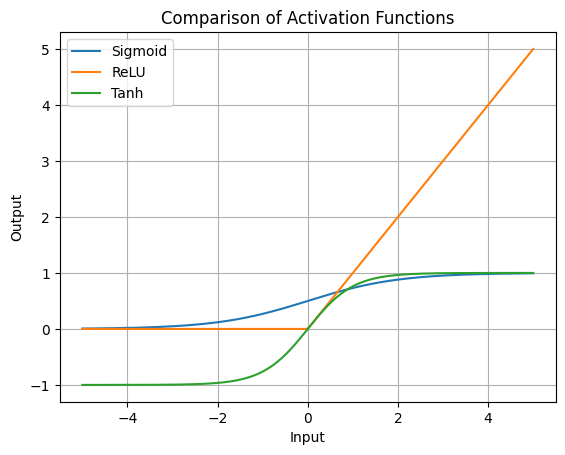

In [3]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

def relu(x):
    return np.maximum(0, x)

def tanh(x):
    return np.tanh(x)


x = np.array([-3, -2, -1, 0, 1, 2, 3])

print("Input values:", x)
print("Sigmoid:", sigmoid(x))
print("ReLU:", relu(x))
print("Tanh:", tanh(x))

x = np.linspace(-5, 5, 200)

plt.plot(x, sigmoid(x), label="Sigmoid")
plt.plot(x, relu(x), label="ReLU")
plt.plot(x, tanh(x), label="Tanh")

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Comparison of Activation Functions")
plt.legend()
plt.grid()

plt.show()

##3.7.3
A cost function measures the accuracy of a neural network making prediction by comparing its predicted values with actual target values. A lower cost indicated that the preidcted probabilty is closer to the actual outcome while a higher cost indicated larger prediction errors. In the example below, 2 sets of probabilities are compared against the same actual outcomes. This helps demonstrate how the cost changes based on the quality of the prediciton.

Actual outcomes: [0 0 1 1]
Predicted probabilities: [0.2 0.3 0.7 0.9]
Binary cross-entropy: 0.2604634874078118
Cost with good predictions: 0.07832690394081712
Cost with poor predictions: 0.698172346466494


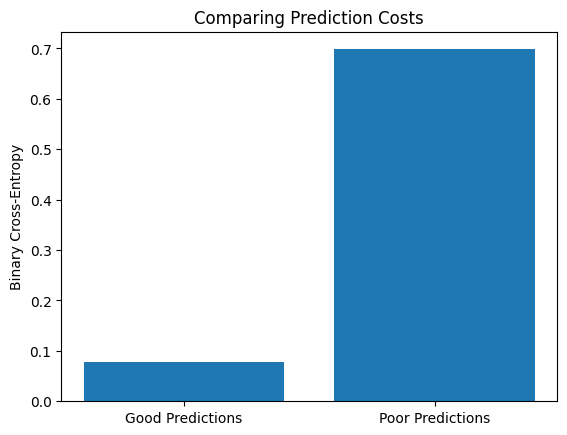

In [4]:
y_true = np.array([0, 0, 1, 1])

y_pred = np.array([0.2, 0.3, 0.7, 0.9])

def binary_cross_entropy(y_true, y_pred):
    eps = 1e-9

    cost = -np.mean(
        y_true * np.log(y_pred + eps) +
        (1 - y_true) * np.log(1 - y_pred + eps)
    )

    return cost

cost = binary_cross_entropy(y_true, y_pred)

print("Actual outcomes:", y_true)
print("Predicted probabilities:", y_pred)
print("Binary cross-entropy:", cost)

good_predictions = np.array([0.05, 0.10, 0.90, 0.95])
poor_predictions = np.array([0.45, 0.55, 0.55, 0.45])

good_cost = binary_cross_entropy(y_true, good_predictions)
poor_cost = binary_cross_entropy(y_true, poor_predictions)

print("Cost with good predictions:", good_cost)
print("Cost with poor predictions:", poor_cost)

plt.bar(
    ["Good Predictions", "Poor Predictions"],
    [good_cost, poor_cost]
)

plt.ylabel("Binary Cross-Entropy")
plt.title("Comparing Prediction Costs")
plt.show()

##3.7.4
Backprograpation is a means for which neural netowkrs calculate how much each weight and bias contributes to the overall prediction error. It works by going backwards from the output layer to the original input layer. It uses derivates and the chain rule to calculate such gradients measuring how much the cost function changes when a particular weight or bais changes. In the example below, the gradients for both hidden and output layers are calculated and dispalyed; the bar graph also provides a visual comparison of the hidden layer weight gradients.

Output layer weight gradients:
[[0.3014]
 [0.2941]
 [0.3014]]

Output layer bias gradients:
[[0.3014]]

Hidden layer weight gradients:
[[0.     0.0149 0.    ]
 [0.     0.0746 0.    ]]

Hidden layer bias gradients:
[[0.     0.0073 0.    ]]


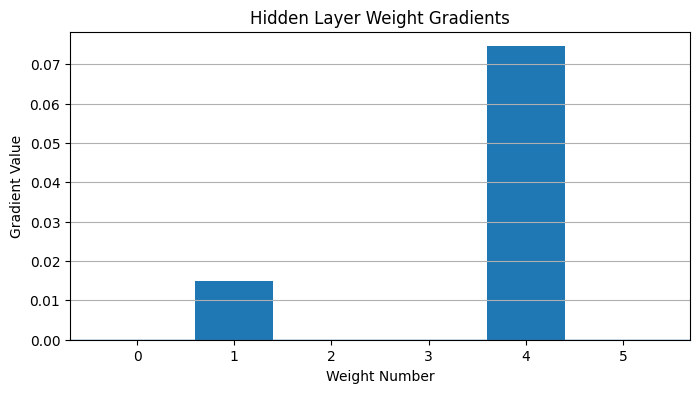

In [10]:
y = np.array([[0], [0], [1], [1]])

z1 = X @ W1 + b1
a1 = np.tanh(z1)

z2 = a1 @ W2 + b2
a2 = sigmoid(z2)

m = len(X)

dz2 = (a2 - y) / m

dW2 = a1.T @ dz2
db2 = np.sum(dz2, axis=0, keepdims=True)

da1 = dz2 @ W2.T
dz1 = da1 * (1 - a1**2)

dW1 = X.T @ dz1
db1 = np.sum(dz1, axis=0, keepdims=True)

print("Output layer weight gradients:")
print(dW2)

print("\nOutput layer bias gradients:")
print(db2)

print("\nHidden layer weight gradients:")
print(dW1)

print("\nHidden layer bias gradients:")
print(db1)

plt.figure(figsize=(8, 4))

plt.bar(
    range(dW1.size),
    dW1.flatten()
)

plt.axhline(0, linewidth=1)
plt.xlabel("Weight Number")
plt.ylabel("Gradient Value")
plt.title("Hidden Layer Weight Gradients")
plt.grid(axis="y")

plt.show()

##3.7.5
The backpropagation algorighm combines forward propagation, gradient calcuation, and descent to train a neurl netowrk. It repeatedly adjusts the weights and biases to reduce prediction error and improve its performace.

In this example belwo, the network is trained across 3000 iterations. During each iteration, it makes predictions, calculates the cost, determines the gradients, and updates its paraemters. The graph demonstrates how the cost chagnes as the nueral netowrk goes through repeated trainign iterations.

Final predicted probabilities:
[[0.    ]
 [0.0006]
 [0.9994]
 [1.    ]]

Final classifications:
[[0]
 [0]
 [1]
 [1]]

Initial cost: 0.6044997058967811
Final cost: 0.0002968023223654017


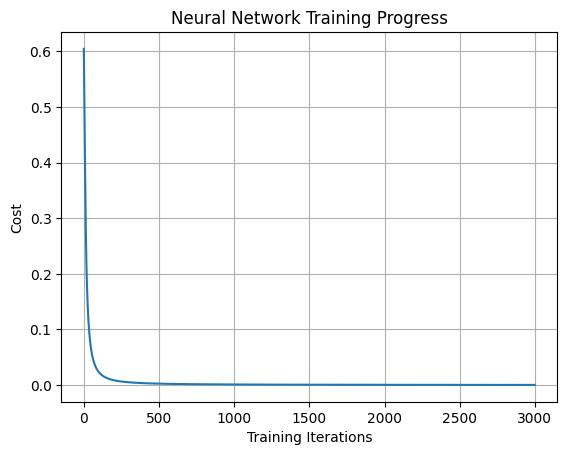

In [11]:
X_train = np.array([
    [0.2, 0.2],
    [0.4, 0.4],
    [0.6, 0.6],
    [0.8, 0.8]
])

y_train = np.array([[0], [0], [1], [1]])

W1 = np.array([
    [0.5, 0.2, 0.4],
    [0.3, 0.6, 0.5]
])

b1 = np.array([-0.3, -0.4, -0.5])

W2 = np.array([
    [0.4],
    [0.3],
    [0.5]
])

b2 = np.array([-0.2])

def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def binary_cross_entropy(y, pred):
    eps = 1e-9
    return -np.mean(
        y * np.log(pred + eps) +
        (1 - y) * np.log(1 - pred + eps)
    )

learning_rate = 1.0
epochs = 3000
losses = []


for step in range(epochs):


    z1 = X_train @ W1 + b1
    a1 = np.tanh(z1)

    z2 = a1 @ W2 + b2
    a2 = sigmoid(z2)

    loss = binary_cross_entropy(y_train, a2)
    losses.append(loss)


    dz2 = (a2 - y_train) / len(X_train)

    dW2 = a1.T @ dz2
    db2 = np.sum(dz2, axis=0)

    da1 = dz2 @ W2.T
    dz1 = da1 * (1 - a1**2)

    dW1 = X_train.T @ dz1
    db1 = np.sum(dz1, axis=0)

    W2 -= learning_rate * dW2
    b2 -= learning_rate * db2

    W1 -= learning_rate * dW1
    b1 -= learning_rate * db1

z1 = X_train @ W1 + b1
a1 = np.tanh(z1)
z2 = a1 @ W2 + b2
final_predictions = sigmoid(z2)

print("Final predicted probabilities:")
print(final_predictions)

print("\nFinal classifications:")
print((final_predictions > 0.5).astype(int))

print("\nInitial cost:", losses[0])
print("Final cost:", losses[-1])

plt.plot(losses)

plt.xlabel("Training Iterations")
plt.ylabel("Cost")
plt.title("Neural Network Training Progress")
plt.grid()

plt.show()

* I explained my sections in words before my code.
* I double checked my core numerical claims
* I changed and/or extended at least one to make this homework my own.
* I ran this from to bottom without issues.
* I am saving this to github under my mat422 repository.